# TP2 — Analyse des accidents routiers avec PySpark

**Contribution — Alex Abdallah (ID16)**

- **Le notebook est-il correct ?** Oui, il a été rejoué du chargement des seize CSV au
  rechargement du modèle de gravité. Les résultats des requêtes comparables concordent
  entre RDD, DataFrame et Spark SQL.
- **Problèmes rencontrés.** Le découpage des lignes à la virgule dépendait de la position des
  champs. La jointure accidents–unités pouvait multiplier le total de victimes. Une colonne
  appelée « date » assemblait en réalité une année, un mois et un jour de semaine. Plusieurs
  exemples récupéraient tous les résultats bruts en mémoire Python.
- **Modifications apportées.** Parseur CSV et colonnes nommées, contrôle des clés et des
  effectifs, jointure par existence pour la question des permis, projections identiques et
  mesures locales dans les trois API. Les analyses de gravité et d’évolution sont conservées.
  Un modèle de gravité est ajusté sur 2012–2017, réglé sur 2018 et évalué sur 2019.
- **Autre information.** Les données d’Australie-Méridionale décrivent des accidents enregistrés.
  Elles ne donnent pas le nombre de trajets sans accident ni l’exposition au trafic.

**Point de départ.** [Étude de Rakesh Nain](https://medium.com/rakesh-nain/big-data-analysis-of-road-crash-data-using-pyspark-with-pyspark-tutorial-c78ff2c35588) ;
[snapshot du code et des CSV](https://github.com/RakeshNain/Big-data-Analysis-of-Road-Crash-Data-using-PySpark-with-PySpark-Tutorial/tree/dab8e6466747903bf1e5bd21ce63fea31bfb6dcc).

## [Data]

### 1.1 Sources et granularité

Les huit fichiers `crash_data/` contiennent une ligne par accident. Les huit fichiers
`units_data/` détaillent les unités impliquées : véhicule, piéton, animal ou obstacle. La clé
`REPORT_ID` relie les tables. Un accident peut correspondre à plusieurs unités et le total de
victimes de l’accident doit être agrégé à cette granularité.

Les CSV de 2012 à 2019 sont contrôlés par SHA-256. Le [dictionnaire des champs](data/metadata-for-road-crash.pdf)
accompagne les données. L’étude utilise Spark en mode local ; les actions telles que `count`
et `show` déclenchent les transformations.

In [1]:
import csv
import hashlib
import json
import os
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.functions import col

base = Path.cwd()
TP = next((p for p in (base, base / "TP2") if (p / "data" / "empreintes.json").is_file()), None)
if TP is None:
    raise FileNotFoundError("Lancer depuis la racine ou TP2/ avec les données du dépôt.")
output_root = os.environ.get("BIGDATA_OUTPUT_ROOT")
OUT = Path(output_root) / "TP2" if output_root else TP / "resultats_road_crash"
OUT.mkdir(parents=True, exist_ok=True)
DATA_ROOT = TP / "data"
source_revision = "dab8e6466747903bf1e5bd21ce63fea31bfb6dcc"
hashes = json.loads((DATA_ROOT / "empreintes.json").read_text(encoding="utf-8"))
sources, manifest = {}, []

for folder in ("crash_data", "units_data"):
    files = sorted((DATA_ROOT / folder).glob("*.csv"))
    if len(files) != 8:
        raise FileNotFoundError(f"Huit fichiers CSV attendus dans {folder}.")
    header = None
    for f in files:
        key = f.relative_to(DATA_ROOT).as_posix()
        with f.open("rb") as stream:
            sha = hashlib.file_digest(stream, "sha256").hexdigest()
        if sha != hashes.get(key):
            raise ValueError(f"Empreinte inattendue : {key}")
        with f.open(encoding="utf-8-sig", newline="") as stream:
            columns = next(csv.reader(stream))
        if header is None:
            header = columns
        assert header == columns, f"En-tête différent dans {key}"
        manifest.append({"fichier": key, "octets": f.stat().st_size, "sha256": sha})
    sources[folder] = (header, [f.resolve().as_uri() for f in files])

os.environ["PYSPARK_PYTHON"] = sys.executable
spark = (SparkSession.builder.master("local[4]").appName("TP2 · Accidents routiers")
         .config("spark.ui.enabled", "false")
         .config("spark.ui.showConsoleProgress", "false")
         .config("spark.driver.host", "127.0.0.1")
         .config("spark.driver.bindAddress", "127.0.0.1")
         .config("spark.driver.memory", "2g")
         .config("spark.sql.shuffle.partitions", "8").getOrCreate())
sc = spark.sparkContext
sc.setLogLevel("ERROR")
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
print(f"{len(manifest)} fichiers vérifiés · Spark {spark.version} · {sc.master}")

16 fichiers vérifiés · Spark 4.0.1 · local[4]


### 1.2 Deux lectures des mêmes fichiers

L’API CSV de Spark alimente les DataFrames. Côté RDD, `csv.reader` interprète les guillemets
puis chaque valeur est associée à son nom de colonne. Les en-têtes sont écartés dans chaque
fichier. La lecture par ligne présuppose un enregistrement par ligne dans ce snapshot ; les
longueurs de lignes et les effectifs sont contrôlés. Les lignes de données restent distribuées.

In [2]:
def lire_dataframe(folder):
    _, paths = sources[folder]
    return spark.read.options(header=True, escape='"', mode="FAILFAST").csv(paths).cache()


def lire_rdd(folder):
    header, paths = sources[folder]

    def parse_line(line):
        values = next(csv.reader([line.removeprefix("\ufeff")], strict=True))
        if not values or values == header:
            return None
        if len(values) != len(header):
            raise ValueError(f"Enregistrement CSV incomplet dans {folder}.")
        return dict(zip(header, values))

    return sc.textFile(",".join(paths)).map(parse_line).filter(lambda row: row is not None)


crash_raw, units_df = (lire_dataframe(p) for p in ("crash_data", "units_data"))
crash_rdd, units_rdd = lire_rdd("crash_data"), lire_rdd("units_data").persist()
n_crash, n_units = crash_raw.count(), units_df.count()
assert n_crash == crash_rdd.count() and n_units == units_rdd.count()
print(f"{n_crash:,} accidents et {n_units:,} unités, mêmes effectifs en RDD et DataFrame.")
crash_raw.select("REPORT_ID", "Year", "Suburb", "CSEF Severity").show(5, truncate=False)
units_df.select("REPORT_ID", "Unit No", "Unit Type", "Veh Reg State").show(5, truncate=False)

127,672 accidents et 272,591 unités, mêmes effectifs en RDD et DataFrame.


+-----------------+----+--------------+-------------+
|REPORT_ID        |Year|Suburb        |CSEF Severity|
+-----------------+----+--------------+-------------+
|2012-1-21/08/2019|2012|STEPNEY       |1: PDO       |
|2012-2-21/08/2019|2012|PARKSIDE      |1: PDO       |
|2012-3-21/08/2019|2012|SELLICKS BEACH|1: PDO       |
|2012-4-21/08/2019|2012|HINDMARSH     |1: PDO       |
|2012-5-21/08/2019|2012|HINDMARSH     |1: PDO       |
+-----------------+----+--------------+-------------+
only showing top 5 rows
+-----------------+-------+------------------+-------------+
|REPORT_ID        |Unit No|Unit Type         |Veh Reg State|
+-----------------+-------+------------------+-------------+
|2012-1-21/08/2019|01     |Pedal Cycle       |NULL         |
|2012-1-21/08/2019|02     |Motor Cars - Sedan|SA           |
|2012-2-21/08/2019|01     |Motor Cars - Sedan|SA           |
|2012-2-21/08/2019|02     |Motor Cars - Sedan|SA           |
|2012-3-21/08/2019|01     |Motor Cars - Sedan|SA           |
+-

## [EDA]

### 2.1 Répartition, âge et année de véhicule avec les RDD

On partitionne les unités selon que l’immatriculation est en Australie-Méridionale (`SA`) ou
ailleurs, valeurs inconnues comprises. Le déséquilibre des partitions montre le *data skew*.
L’âge moyen est calculé avec somme et effectif par sexe déclaré. Les valeurs non numériques
de l’âge et de l’année du véhicule sont écartées pour ces agrégats.

In [3]:
repartitionne = (units_rdd.map(lambda row: (row["Veh Reg State"], 1))
                 .partitionBy(2, lambda etat: 0 if etat == "SA" else 1))
tailles = repartitionne.mapPartitions(lambda lignes: [sum(1 for _ in lignes)]).collect()
assert sum(tailles) == n_units
display(pd.Series(tailles, index=["SA", "Hors SA ou inconnu"], name="Unités").to_frame())

ages = (units_rdd.filter(lambda r: r["Age"].isascii() and r["Age"].isdigit()
                         and r["Sex"] not in {"", "Unknown"})
        .map(lambda r: (r["Sex"], (int(r["Age"]), 1)))
        .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1])))
display(pd.DataFrame([(sexe, n, somme / n) for sexe, (somme, n) in sorted(ages.collect())],
                     columns=["Sexe renseigné", "Effectif", "Âge moyen"]).round(2))

millesimes = (units_rdd.filter(lambda r: r["Veh Year"].isascii() and r["Veh Year"].isdigit())
              .map(lambda r: (int(r["Veh Year"]), r["Veh Reg State"], r["Unit Type"])))
print("Trois unités aux millésimes les plus anciens :", millesimes.takeOrdered(3))
print("Trois unités aux millésimes les plus récents :", millesimes.takeOrdered(3, key=lambda r: -r[0]))
units_rdd.unpersist()

,Unités
SA,218366
Hors SA ou inconnu,54225


,Sexe renseigné,Effectif,Âge moyen
0,Female,85603,40.08
1,Male,131892,40.80


Trois unités aux millésimes les plus anciens : [(1900, 'SA', 'Motor Cycle'), (1900, 'SA', 'Motor Cycle'), (1900, 'SA', 'Motor Cycle')]


Trois unités aux millésimes les plus récents : [(2019, 'SA', 'Station Wagon'), (2019, 'SA', 'OMNIBUS'), (2019, 'SA', 'Motor Cars - Sedan')]


PythonRDD[24] at RDD at PythonRDD.scala:56

### 2.2 Gravité selon les indicateurs d’alcool et de stupéfiants

Les niveaux sont matériel seul (`1: PDO`), blessures légères (`2: MI`), blessures graves
(`3: SI`) et accident mortel (`4: Fatal`). On forme quatre groupes exclusifs à partir des
signalements `Y`. Deux signalements peuvent concerner des personnes différentes. L’absence
de `Y` signifie uniquement « pas de signalement dans le champ » ; elle ne prouve pas un test négatif.

In [4]:
severity_labels = {"1: PDO": "Matériel seul", "2: MI": "Blessures légères",
                   "3: SI": "Blessures graves", "4: Fatal": "Mortel"}
severity_order = list(severity_labels)
assert {r[0] for r in crash_raw.select("CSEF Severity").distinct().collect()} == set(severity_order)
crash_df = crash_raw

,groupe,CSEF Severity,count,total_groupe,part_pct
0,Alcool Y sans stupéfiants Y,1: PDO,2108,3681,57.27
1,Alcool Y sans stupéfiants Y,2: MI,1092,3681,29.67
2,Alcool Y sans stupéfiants Y,3: SI,384,3681,10.43
3,Alcool Y sans stupéfiants Y,4: Fatal,97,3681,2.64
4,Aucun signalement Y,1: PDO,82430,122137,67.49
5,Aucun signalement Y,2: MI,35099,122137,28.74
6,Aucun signalement Y,3: SI,4100,122137,3.36
7,Aucun signalement Y,4: Fatal,508,122137,0.42
8,Deux indicateurs Y,1: PDO,36,298,12.08
9,Deux indicateurs Y,2: MI,151,298,50.67


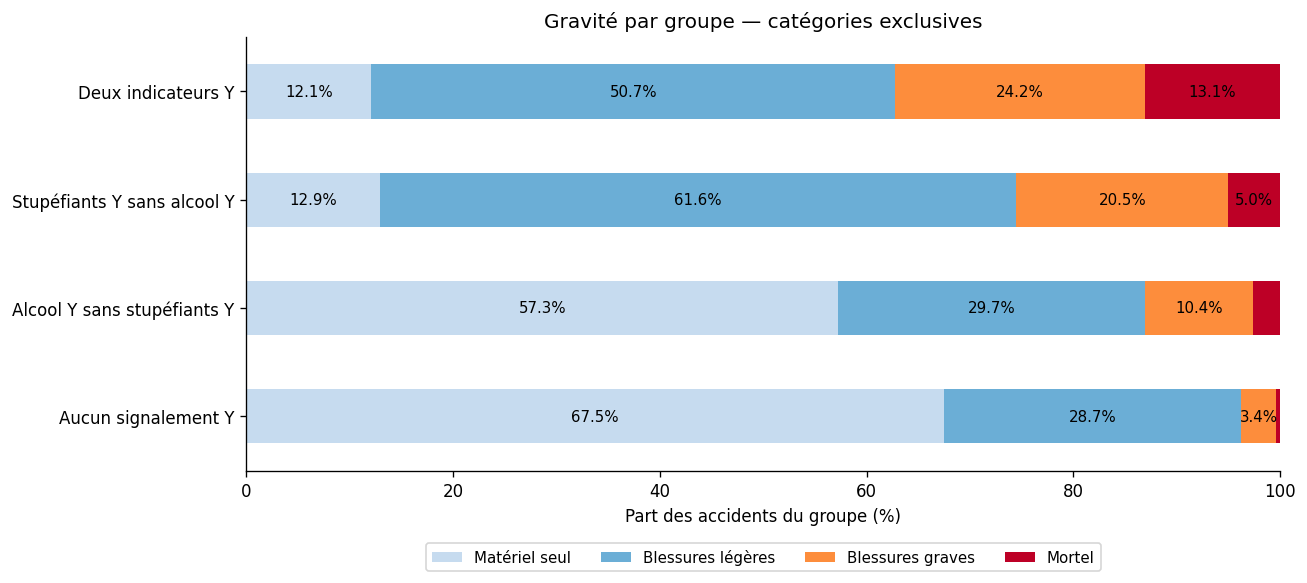

In [5]:
from pyspark.sql import Window
alcohol_y = F.coalesce(col("DUI Involved") == "Y", F.lit(False))
drugs_y = F.coalesce(col("Drugs Involved") == "Y", F.lit(False))
labeled = crash_df.withColumn("groupe",
    F.when(alcohol_y & drugs_y, "Deux indicateurs Y")
     .when(alcohol_y, "Alcool Y sans stupéfiants Y")
     .when(drugs_y, "Stupéfiants Y sans alcool Y")
     .otherwise("Aucun signalement Y"))
exclusive_labels = ["Aucun signalement Y", "Alcool Y sans stupéfiants Y",
                    "Stupéfiants Y sans alcool Y", "Deux indicateurs Y"]
grid = (spark.createDataFrame([(g,) for g in exclusive_labels], ["groupe"])
    .crossJoin(spark.createDataFrame([(s,) for s in severity_order], ["CSEF Severity"])))
exclusive_stats = (grid.join(labeled.groupBy("groupe", "CSEF Severity").count(),
                            ["groupe", "CSEF Severity"], "left").fillna(0, ["count"])
    .withColumn("total_groupe", F.sum("count").over(Window.partitionBy("groupe")))
    .withColumn("part_pct", F.when(col("total_groupe") > 0, 100 * col("count") / col("total_groupe"))))
exclusive_pd = exclusive_stats.toPandas()
assert int(exclusive_pd["count"].sum()) == n_crash
assert all(abs(x - 100) < 1e-8 for x in exclusive_pd.groupby("groupe")["part_pct"].sum())
display(exclusive_pd.sort_values(["groupe", "CSEF Severity"]).round(2))
table = exclusive_pd.pivot(index="groupe", columns="CSEF Severity", values="part_pct").reindex(index=exclusive_labels, columns=severity_order)
table.columns = [severity_labels[s] for s in table.columns]
fig, ax = plt.subplots(figsize=(11, 5))
table.plot.barh(stacked=True, ax=ax, color=["#c6dbef", "#6baed6", "#fd8d3c", "#bd0026"])
for container in ax.containers:
    ax.bar_label(container, labels=[f"{v:.1f}%" if v >= 3 else "" for v in container.datavalues], label_type="center", fontsize=9)
ax.set(xlim=(0, 100), xlabel="Part des accidents du groupe (%)", ylabel="", title="Gravité par groupe — catégories exclusives")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4, fontsize=9)
fig.tight_layout()
fig.savefig(OUT / "03_gravite_groupes_exclusifs.png", bbox_inches="tight")
plt.show()

**Lecture.** Le graphique compare des proportions à l’intérieur de chaque groupe. Une part plus
élevée d’accidents graves dans un groupe ne mesure ni un risque absolu ni un effet causal.

## [Prétraitement]

### 3.1 Contrôler les clés, typer les comptes et préparer la cible

Un accident est unique par `REPORT_ID` et une unité par (`REPORT_ID`, `Unit No`). On vérifie
aussi qu’aucune unité n’est orpheline. Les compteurs de victimes sont convertis en entiers et
contrôlés par identité comptable. Les heures illisibles restent nulles. La cible binaire vaut 1
pour un accident grave ou mortel et 0 sinon.

In [6]:
assert not crash_raw.where(col("REPORT_ID").isNull()).limit(1).count()
assert not units_df.where(col("REPORT_ID").isNull() | col("Unit No").isNull()).limit(1).count()
assert not crash_raw.groupBy("REPORT_ID").count().where("count > 1").limit(1).count()
assert not units_df.groupBy("REPORT_ID", "Unit No").count().where("count > 1").limit(1).count()
assert not units_df.join(crash_raw.select("REPORT_ID"), "REPORT_ID", "left_anti").limit(1).count()

numeriques = ["Year", "Total Cas", "Total Fats", "Total SI", "Total MI"]
crash_typed = (crash_raw.withColumns({c: F.expr(f"try_cast(`{c}` as int)") for c in numeriques})
               .withColumn("label", col("CSEF Severity").isin("3: SI", "4: Fatal").cast("double"))
               .cache())
assert crash_typed.dropna(subset=numeriques).count() == n_crash
assert {r[0] for r in crash_typed.select("Year").distinct().collect()} == set(range(2012, 2020))
assert not crash_typed.where(col("Total Cas") != col("Total Fats") + col("Total SI") + col("Total MI")).limit(1).count()
summary = crash_typed.agg(F.count("*").alias("accidents"), F.sum("Total Cas").alias("victimes"),
                          F.sum("Total Fats").alias("deces"), F.sum("Total SI").alias("blesses_graves"),
                          F.sum("Total MI").alias("blesses_legers")).first().asDict()
crash_raw.unpersist()
crash_df = crash_typed
display(pd.DataFrame([summary]))

,accidents,victimes,deces,blesses_graves,blesses_legers
0,127672,53255,781,5744,46730


## [Transformation]

### 4.1 Accidents à Adelaide : les mêmes champs dans les trois API

Une ligne décrit une unité impliquée. Les victimes de l’unité et celles de l’accident restent
distinctes. `Day` contient le jour de semaine : les colonnes année, mois, jour de semaine et
heure sont conservées séparément. `exceptAll` vérifie les valeurs et leurs multiplicités.

In [7]:
crash_df.createOrReplaceTempView("accidents")
units_df.createOrReplaceTempView("unites")
c_fields = ["REPORT_ID", "Suburb", "Year", "Month", "Day", "Time", "Total Cas"]
u_fields = ["REPORT_ID", "Unit No", "No Of Cas", "Sex", "Age", "Licence Type"]
c_pairs = crash_df.select(*c_fields).rdd.map(lambda r: (r.REPORT_ID, r.asDict()))
u_pairs = units_df.select(*u_fields).rdd.map(lambda r: (r.REPORT_ID, r.asDict()))

adelaide_df = (crash_df.alias("c").join(units_df.alias("u"), "REPORT_ID")
    .where(col("c.Suburb") == "ADELAIDE")
    .select("REPORT_ID", "u.Unit No", "c.Year", "c.Month", "c.Day", "c.Time", "u.Sex", "u.Age",
            "u.Licence Type", col("u.No Of Cas").cast("int").alias("victimes_unite"),
            col("c.Total Cas").alias("victimes_accident")))
adelaide_sql = spark.sql("""
    SELECT c.REPORT_ID, u.`Unit No`, c.Year, c.Month, c.Day, c.Time, u.Sex, u.Age, u.`Licence Type`,
           CAST(u.`No Of Cas` AS INT) AS victimes_unite, c.`Total Cas` AS victimes_accident
    FROM accidents c JOIN unites u ON c.REPORT_ID = u.REPORT_ID
    WHERE c.Suburb = 'ADELAIDE'
""")

def projeter_unite(record):
    key, (c, u) = record
    victimes_unite = None if u["No Of Cas"] is None else int(u["No Of Cas"])
    return (key, u["Unit No"], c["Year"], c["Month"], c["Day"], c["Time"], u["Sex"], u["Age"],
            u["Licence Type"], victimes_unite, c["Total Cas"])


adelaide_rdd = (c_pairs.filter(lambda kv: kv[1]["Suburb"] == "ADELAIDE")
                .join(u_pairs).map(projeter_unite))
adelaide_rdd_df = spark.createDataFrame(adelaide_rdd, adelaide_df.schema)

def assert_same_rows(left, right):
    assert left.dtypes == right.dtypes, "Colonnes ou types différents"
    assert not left.exceptAll(right).limit(1).count(), "Ligne excédentaire à gauche"
    assert not right.exceptAll(left).limit(1).count(), "Ligne excédentaire à droite"


assert_same_rows(adelaide_df, adelaide_sql)
assert_same_rows(adelaide_df, adelaide_rdd_df)
print("RDD, DataFrame et SQL : mêmes lignes pour Adelaide.")
adelaide_df.orderBy("REPORT_ID", "Unit No").show(8, truncate=False)

RDD, DataFrame et SQL : mêmes lignes pour Adelaide.


+---------------------+-------+----+-----+---------+--------+------+---+------------+--------------+-----------------+
|REPORT_ID            |Unit No|Year|Month|Day      |Time    |Sex   |Age|Licence Type|victimes_unite|victimes_accident|
+---------------------+-------+----+-----+---------+--------+------+---+------------+--------------+-----------------+
|2012-10007-21/08/2019|01     |2012|June |Wednesday|05:30 pm|Female|036|Unknown     |0             |0                |
|2012-10007-21/08/2019|02     |2012|June |Wednesday|05:30 pm|Male  |XXX|Unknown     |0             |0                |
|2012-10027-21/08/2019|01     |2012|June |Thursday |02:45 pm|Male  |062|Full        |0             |0                |
|2012-10027-21/08/2019|02     |2012|June |Thursday |02:45 pm|Female|020|Full        |0             |0                |
|2012-10040-21/08/2019|01     |2012|June |Thursday |05:24 pm|Male  |049|Full        |0             |1                |
|2012-10040-21/08/2019|02     |2012|June |Thursd

### 4.2 Victimes et accidents avec au moins une unité sans permis

`Unlicenced` est le libellé du CSV. La jointure directe lue dans l’étude de départ répète les
victimes de l’accident lorsqu’il y a plusieurs unités sans permis. Avec `left_semi` en DataFrame,
`EXISTS` en SQL et une clé dédoublonnée en RDD, chaque accident contribue une seule fois.

In [8]:
sans_permis = units_df.where(col("Licence Type") == "Unlicenced").select("REPORT_ID")
original_total = crash_df.join(sans_permis, "REPORT_ID").agg(F.sum("Total Cas")).first()[0]
unlicensed_corrected = (crash_df.join(sans_permis, "REPORT_ID", "left_semi").groupBy("Suburb")
                        .agg(F.count("*").alias("accidents"), F.sum("Total Cas").alias("victimes")))
unlicensed_corrected_sql = spark.sql("""
    SELECT c.Suburb, COUNT(*) AS accidents, SUM(c.`Total Cas`) AS victimes
    FROM accidents c WHERE EXISTS (
        SELECT 1 FROM unites u WHERE u.REPORT_ID = c.REPORT_ID AND u.`Licence Type` = 'Unlicenced'
    ) GROUP BY c.Suburb
""")
sans_permis_keys = (u_pairs.filter(lambda kv: kv[1]["Licence Type"] == "Unlicenced")
                    .mapValues(lambda _: 1).reduceByKey(lambda a, b: 1))
unlicensed_result_rdd = (c_pairs.join(sans_permis_keys)
    .map(lambda kv: (kv[1][0]["Suburb"], (1, kv[1][0]["Total Cas"])))
    .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))
    .map(lambda kv: (kv[0], kv[1][0], kv[1][1])))
unlicensed_rdd_df = spark.createDataFrame(unlicensed_result_rdd, unlicensed_corrected.schema)
assert_same_rows(unlicensed_corrected, unlicensed_corrected_sql)
assert_same_rows(unlicensed_corrected, unlicensed_rdd_df)
cols = unlicensed_corrected.columns
corrected_total = unlicensed_corrected.agg(F.sum("victimes")).first()[0]
print(f"Victimes après jointure directe : {original_total:,} ; par accident unique : {corrected_total:,}.")
unlicensed_corrected.orderBy(F.desc("victimes"), "Suburb").show(10, truncate=False)

Victimes après jointure directe : 2,072 ; par accident unique : 2,053.


+--------------+---------+--------+
|Suburb        |accidents|victimes|
+--------------+---------+--------+
|ADELAIDE      |149      |42      |
|SALISBURY     |40       |30      |
|PROSPECT      |48       |27      |
|INGLE FARM    |32       |22      |
|MORPHETT VALE |49       |20      |
|DRY CREEK     |19       |19      |
|MURRAY BRIDGE |30       |19      |
|SALISBURY EAST|30       |19      |
|MAWSON LAKES  |36       |17      |
|NORTH ADELAIDE|42       |17      |
+--------------+---------+--------+
only showing top 10 rows


### 4.3 Mesures de performance sur la requête sans permis

Après un échauffement par API, trois actions `collect` ramènent les agrégats. L’ordre tourne à
chaque répétition. DataFrame et SQL passent par le même optimiseur ; l’API RDD fait intervenir
des opérations Python. L’expérience décrit les trois implémentations sur une machine locale.

,API,Essai 1 (s),Essai 2 (s),Essai 3 (s),Médiane (s)
0,RDD,0.340,0.382,0.302,0.340
1,DataFrame,0.036,0.041,0.040,0.040
2,Spark SQL,0.037,0.042,0.045,0.042


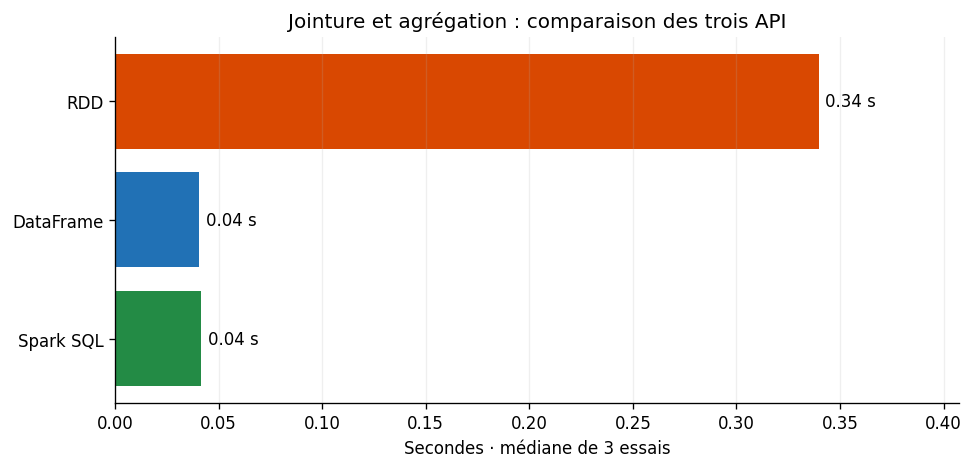

In [9]:
from statistics import median
from time import perf_counter

def resultat_localite(lignes):
    return {(r[0], r[1], r[2]) for r in lignes}

requetes = {
    "RDD": unlicensed_result_rdd,
    "DataFrame": unlicensed_corrected.select(*cols),
    "Spark SQL": unlicensed_corrected_sql.select(*cols),
}
reference_api = resultat_localite(requetes["DataFrame"].collect())
for requete in requetes.values():
    assert resultat_localite(requete.collect()) == reference_api
temps_api = {api: [] for api in requetes}
ordre = list(requetes)
for repetition in range(3):
    for api in ordre[repetition:] + ordre[:repetition]:
        debut = perf_counter()
        lignes = requetes[api].collect()
        temps_api[api].append(perf_counter() - debut)
        assert resultat_localite(lignes) == reference_api
benchmark_pd = pd.DataFrame([
    {"API": api, **{f"Essai {i} (s)": t for i, t in enumerate(durees, 1)}, "Médiane (s)": median(durees)}
    for api, durees in temps_api.items()
])
display(benchmark_pd.round(3))
fig, ax = plt.subplots(figsize=(8, 3.8), layout="constrained")
bars = ax.barh(benchmark_pd["API"], benchmark_pd["Médiane (s)"], color=["#d94801", "#2171b5", "#238b45"])
ax.invert_yaxis()
ax.bar_label(bars, fmt="%.2f s", padding=4)
ax.margins(x=0.2)
ax.set(xlabel="Secondes · médiane de 3 essais", title="Jointure et agrégation : comparaison des trois API")
ax.grid(axis="x", alpha=0.2)
fig.savefig(OUT / "06_benchmark_api.png", bbox_inches="tight")
plt.show()

### 4.4 Évolution annuelle, décès par type et gravité selon l’heure

Les nombres d’accidents enregistrés sont des volumes. Les parts calculées par heure décrivent
la gravité parmi les accidents de chaque tranche, sans normalisation par le trafic.

,Year,accidents,victimes,deces,graves_ou_mortels,part_graves_ou_mortels_pct
0,2012,22829,7479,94,723,3.17
1,2013,16675,7177,97,755,4.53
2,2014,16162,6982,108,690,4.27
3,2015,15431,6660,102,753,4.88
4,2016,16775,6565,86,651,3.88
5,2017,13237,6237,100,626,4.73
6,2018,13599,6124,80,560,4.12
7,2019,12964,6031,114,839,6.47


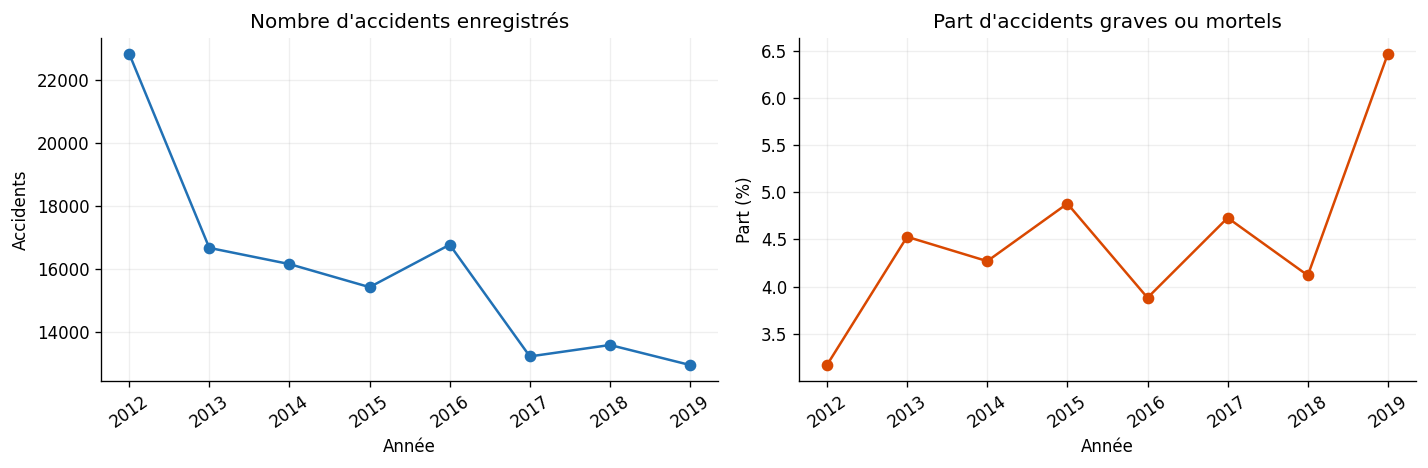

In [10]:
annual = (crash_typed.groupBy("Year").agg(F.count("*").alias("accidents"),
    F.sum("Total Cas").alias("victimes"), F.sum("Total Fats").alias("deces"),
    F.sum(col("CSEF Severity").isin("3: SI", "4: Fatal").cast("int")).alias("graves_ou_mortels"))
    .withColumn("part_graves_ou_mortels_pct", 100 * col("graves_ou_mortels") / col("accidents"))
    .orderBy("Year"))
annual_pd = annual.toPandas()
display(annual_pd.round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(annual_pd["Year"], annual_pd["accidents"], marker="o", color="#2171b5")
axes[0].set(title="Nombre d'accidents enregistrés", xlabel="Année", ylabel="Accidents")
axes[1].plot(annual_pd["Year"], annual_pd["part_graves_ou_mortels_pct"], marker="o", color="#d94801")
axes[1].set(title="Part d'accidents graves ou mortels", xlabel="Année", ylabel="Part (%)")
for ax in axes:
    ax.set_xticks(annual_pd["Year"])
    ax.tick_params(axis="x", rotation=35)
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUT / "04_evolution_annuelle.png", bbox_inches="tight")
plt.show()

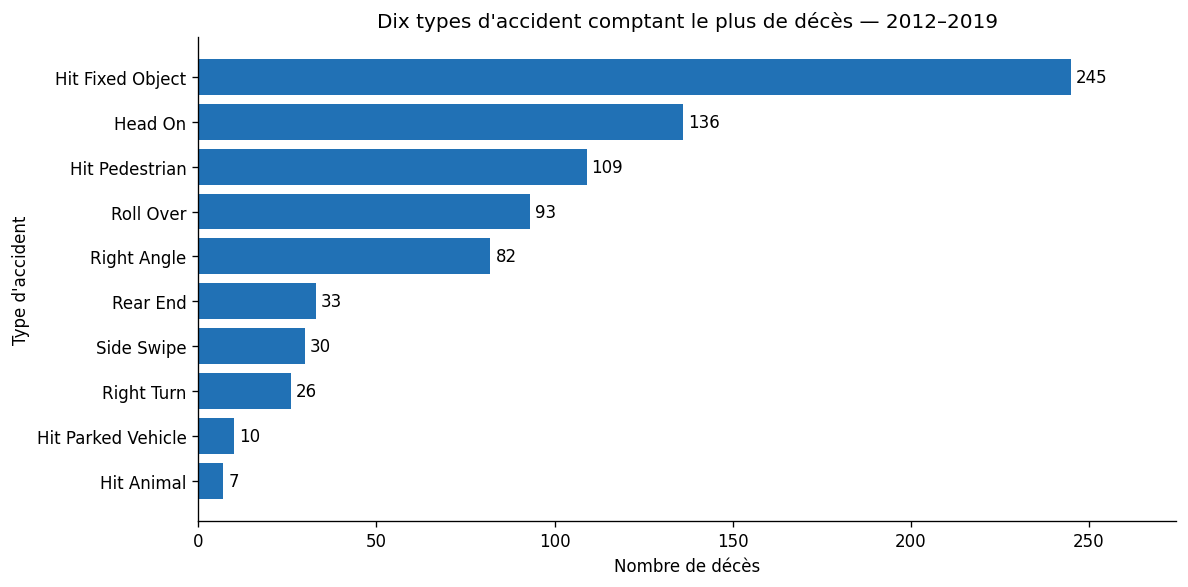

In [11]:
# Ajout : conserver la table agrégée et tracer les dix premières catégories.
fatalities_by_type = (crash_df.groupBy("Crash Type")
    .agg(F.sum("Total Fats").alias("Total fatalities"))
    .orderBy(F.desc("Total fatalities"), "Crash Type"))
fatalities_type_pd = fatalities_by_type.toPandas()
p = fatalities_type_pd.head(10).sort_values("Total fatalities")
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(p["Crash Type"], p["Total fatalities"], color="#2171b5")
ax.bar_label(ax.containers[0], padding=3, fmt="%.0f")
ax.set(xlabel="Nombre de décès", ylabel="Type d'accident",
       title="Dix types d'accident comptant le plus de décès — 2012–2019")
ax.margins(x=0.12)
fig.tight_layout()
fig.savefig(OUT / "01_deces_par_type.png", bbox_inches="tight")
plt.show()

Heure absente ou illisible : 0 accidents


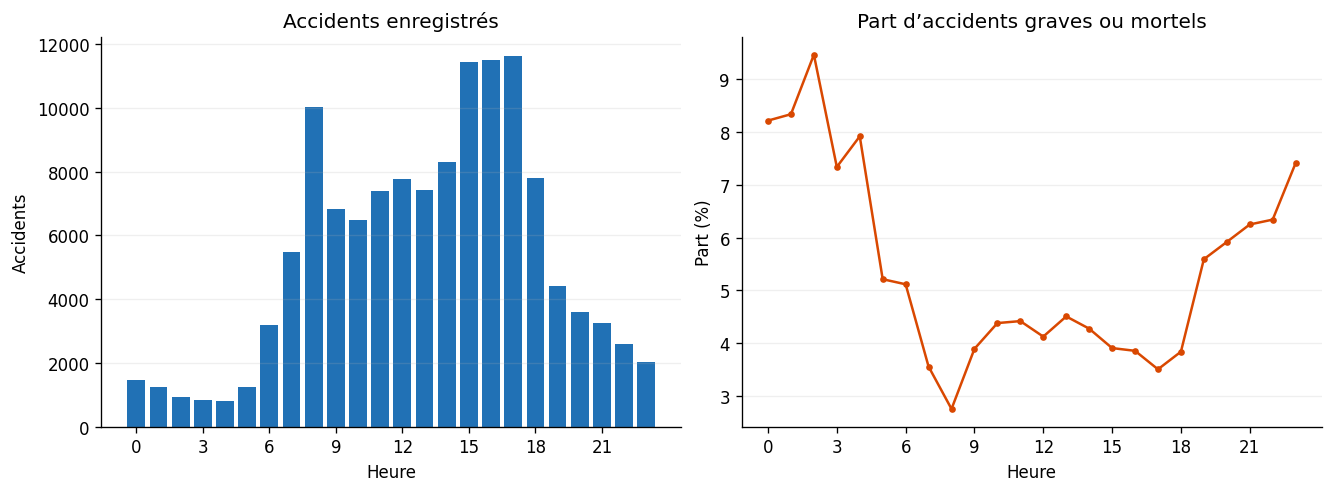

In [12]:
heures = (crash_typed
    .withColumn("heure", F.hour(F.try_to_timestamp(F.upper(F.trim("Time")), F.lit("hh:mm a"))))
    .groupBy("heure")
    .agg(F.count("*").alias("accidents"),
         F.sum(F.col("CSEF Severity").isin("3: SI", "4: Fatal").cast("int")).alias("graves_ou_mortels"))
    .orderBy("heure").toPandas())
assert int(heures["accidents"].sum()) == n_crash
inconnues = int(heures.loc[heures["heure"].isna(), "accidents"].sum())
print(f"Heure absente ou illisible : {inconnues:,} accidents")
heures_pd = heures.dropna(subset=["heure"]).copy()
heures_pd["heure"] = heures_pd["heure"].astype(int)
assert set(heures_pd["heure"]) == set(range(24))
heures_pd["part_graves_ou_mortels_pct"] = 100 * heures_pd["graves_ou_mortels"] / heures_pd["accidents"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
axes[0].bar(heures_pd["heure"], heures_pd["accidents"], color="#2171b5")
axes[0].set(title="Accidents enregistrés", ylabel="Accidents")
axes[1].plot(heures_pd["heure"], heures_pd["part_graves_ou_mortels_pct"], color="#d94801", marker=".")
axes[1].set(title="Part d’accidents graves ou mortels", ylabel="Part (%)")
for ax in axes:
    ax.set(xlabel="Heure", xticks=range(0, 24, 3))
    ax.grid(axis="y", alpha=0.2)
fig.savefig(OUT / "05_gravite_par_heure.png", bbox_inches="tight")
plt.show()

## [ML]

### 5.1 Modéliser la gravité à partir du contexte

Exercice de classification **parmi les accidents enregistrés**. Les variables d’entrée sont
l’heure, le jour de semaine, la météo, l’état de la chaussée, la luminosité et la vitesse de
la zone. La gravité enregistrée, les blessures et les signalements relevés après l’accident
ne sont pas des entrées du modèle.

La régression logistique et l’encodage sont ajustés sur **2012–2017**. Le seuil est choisi en
**2018** en maximisant le F1 de la classe grave parmi 50 seuils de 0,01 à 0,50. **2019** est
réservé à l’évaluation. Le F1 combine précision et rappel sans faire intervenir les vrais négatifs.

In [13]:
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.feature import OneHotEncoder, SQLTransformer, StringIndexer, VectorAssembler
from pyspark.ml.functions import vector_to_array

INPUTS = ["Time", "Day", "Weather Cond", "Road Surface", "DayNight", "Area Speed"]
categoriels = ["heure", *INPUTS[1:]]
indices = [f"categorie_{i}" for i in range(len(categoriels))]
one_hot = [f"vecteur_{i}" for i in range(len(categoriels))]
preparation = SQLTransformer(statement="""
    SELECT *, CAST(HOUR(TRY_TO_TIMESTAMP(UPPER(TRIM(`Time`)), 'hh:mm a')) AS STRING) AS heure
    FROM __THIS__
""")
pipeline = Pipeline(stages=[
    preparation,
    StringIndexer(inputCols=categoriels, outputCols=indices, handleInvalid="keep"),
    OneHotEncoder(inputCols=indices, outputCols=one_hot, handleInvalid="keep"),
    VectorAssembler(inputCols=one_hot, outputCol="features"),
    LogisticRegression(maxIter=35, regParam=0.01),
])

splits = {"Apprentissage 2012–2017": crash_df.where(col("Year") < 2018),
          "Validation 2018": crash_df.where(col("Year") == 2018),
          "Test 2019": crash_df.where(col("Year") == 2019)}
tailles = {nom: subset.count() for nom, subset in splits.items()}
assert sum(tailles.values()) == n_crash and all(tailles.values())
display(pd.Series(tailles, name="Accidents").to_frame())
train, val, test = splits.values()
model = pipeline.fit(train.select(*INPUTS, "label"))

val_scores = model.transform(val.select(*INPUTS, "label")).select(
    "label", vector_to_array("probability")[1].alias("score")).cache()
candidats = spark.range(1, 51).select((col("id") / 100.0).alias("seuil"))
val_metrics = (val_scores.crossJoin(candidats).groupBy("seuil").agg(
    F.sum(((col("label") == 1) & (col("score") > col("seuil"))).cast("long")).alias("tp"),
    F.sum(((col("label") == 0) & (col("score") > col("seuil"))).cast("long")).alias("fp"),
    F.sum((col("label") == 1).cast("long")).alias("positifs"))
    .withColumn("f1", F.try_divide(2 * col("tp"), col("tp") + col("fp") + col("positifs"))))
meilleur = val_metrics.orderBy(F.desc("f1"), "fp", F.desc("seuil")).first()
assert meilleur.positifs > 0
seuil = float(meilleur.seuil)
model.stages[-1].setThreshold(seuil)
val_scores.unpersist()
print(f"Seuil retenu sur 2018 : {seuil:.2f} · F1 grave : {meilleur.f1:.3f}")

,Accidents
Apprentissage 2012–2017,101109
Validation 2018,13599
Test 2019,12964


Seuil retenu sur 2018 : 0.08 · F1 grave : 0.212


## [Éval]

### 6.1 Test chronologique et comparaison à une règle simple

La classe grave est rare. On compare la régression à une règle qui classe chaque accident
« non grave ». On lit l’aire sous précision–rappel (AUC PR ; repère = prévalence), le rappel
de la classe grave, la précision et le nombre de fausses alertes au seuil décidé sur 2018.

In [14]:
from pyspark.ml.evaluation import BinaryClassificationEvaluator

predicted = model.transform(test.select(*INPUTS, "label")).select(
    "label", "prediction", vector_to_array("probability")[1].alias("score")).cache()
evaluateur = BinaryClassificationEvaluator(rawPredictionCol="score", metricName="areaUnderPR")
auc_pr = evaluateur.evaluate(predicted)
matrice = np.zeros((2, 2), dtype=np.int64)
for row in predicted.groupBy("label", "prediction").count().collect():
    matrice[int(row.label), int(row.prediction)] = row["count"]
tn, fp, fn, tp = map(int, matrice.ravel())
assert tn + fp > 0 and tp + fn > 0 and matrice.sum() == tailles["Test 2019"]
prevalence = (tp + fn) / int(matrice.sum())
precision = tp / (tp + fp) if tp + fp else 0.0
rappel = tp / (tp + fn)
f1 = 2 * tp / (2 * tp + fp + fn)
scorecard = pd.DataFrame([
    {"Modèle": "Toujours non grave", "AUC PR / repère": prevalence, "Précision grave": 0.,
     "Rappel grave": 0., "F1 grave": 0., "Fausses alertes": 0},
    {"Modèle": "Régression logistique", "AUC PR / repère": auc_pr, "Précision grave": precision,
     "Rappel grave": rappel, "F1 grave": f1, "Fausses alertes": fp},
]).set_index("Modèle")
display(scorecard.round(4))
display(pd.DataFrame(matrice, index=pd.Index(["Non grave", "Grave"], name="Réel"),
                     columns=pd.Index(["Non grave", "Grave"], name="Prédit")))
display(Markdown(f"Sur 2019, **{tp} accidents graves sur {tp + fn}** sont détectés. "
                 f"La règle déclenche aussi **{fp:,} fausses alertes**. Le déséquilibre des classes "
                 "explique pourquoi l’exactitude seule serait trompeuse."))
predicted.unpersist()

,AUC PR / repère,Précision grave,Rappel grave,F1 grave,Fausses alertes
Modèle,,,,,
Toujours non grave,0.0647,0.0000,0.0000,0.0000,0
Régression logistique,0.1352,0.1802,0.3015,0.2256,1151


Prédit,Non grave,Grave
Réel,,
Non grave,10974,1151
Grave,586,253


Sur 2019, **253 accidents graves sur 839** sont détectés. La règle déclenche aussi **1,151 fausses alertes**. Le déséquilibre des classes explique pourquoi l’exactitude seule serait trompeuse.

DataFrame[label: double, prediction: double, score: double]

## [Déploiement]

### 7.1 Export et essai sur un lot sans étiquette

Le `PipelineModel` réunit la préparation horaire, l’encodage, la régression et le seuil. On
l’enregistre, puis on le recharge pour traiter un CSV ne contenant que les six champs d’entrée.
On vérifie que les scores et les décisions sont inchangés après rechargement.

In [15]:
modele_uri = (OUT / "modele_gravite_spark").resolve().as_uri()
model.write().overwrite().save(modele_uri)
reloaded = PipelineModel.load(modele_uri)
exemple_csv = OUT / "exemple_contexte.csv"
test.orderBy("REPORT_ID").select(*INPUTS).limit(5).toPandas().to_csv(exemple_csv, index=False)
sans_etiquette = (spark.read.options(header=True, mode="FAILFAST")
                  .csv(exemple_csv.resolve().as_uri()).select(*INPUTS))

def predire(modele, lignes):
    return modele.transform(lignes).select(*INPUTS,
        vector_to_array("probability")[1].alias("score_grave"),
        col("prediction").cast("int").alias("classe_grave"))


scores = predire(model, sans_etiquette).orderBy(*INPUTS).collect()
export = predire(reloaded, sans_etiquette).orderBy(*INPUTS).toPandas()
assert len(export) == len(scores) == 5
np.testing.assert_allclose(export["score_grave"], [row.score_grave for row in scores])
assert export["classe_grave"].tolist() == [row.classe_grave for row in scores]
display(export)
export.to_csv(OUT / "predictions_gravite.csv", index=False)
pd.DataFrame(manifest).to_csv(OUT / "manifest_sources.csv", index=False)
annual_pd.to_csv(OUT / "bilan_annuel.csv", index=False)
exclusive_pd.to_csv(OUT / "gravite_groupes_exclusifs.csv", index=False)
benchmark_pd.to_csv(OUT / "benchmark_api_spark.csv", index=False)
unlicensed_corrected.orderBy("Suburb").toPandas().to_csv(OUT / "sans_permis_par_localite.csv", index=False)
rapport = {"revision_source": source_revision, "spark": spark.version, "colonnes_entree": INPUTS,
           "seuil": seuil, "matrice_test_2019": matrice.tolist(), "metriques": scorecard.to_dict(orient="index")}
(OUT / "metriques_gravite.json").write_text(json.dumps(rapport, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
spark.stop()

,Time,Day,Weather Cond,Road Surface,DayNight,Area Speed,score_grave,classe_grave
0,02:50 pm,Wednesday,Not Raining,Sealed,Daylight,060,0.025263,0
1,04:10 pm,Saturday,Not Raining,Sealed,Daylight,060,0.029177,0
2,10:07 am,Sunday,Not Raining,Sealed,Daylight,060,0.033672,0
3,11:15 am,Wednesday,Not Raining,Sealed,Daylight,060,0.025845,0
4,12:30 pm,Tuesday,Not Raining,Sealed,Daylight,080,0.050058,0


## [Conclusion]

Les trois API donnent les mêmes résultats lorsque la clé, la granularité et les colonnes sont
définies de la même façon. La jointure corrigée répond à la question initiale : combien de
victimes dans des accidents impliquant au moins une unité sans permis ? Les écarts de durée
reflètent les appels et les échanges de données de ce notebook sur un seul poste.

La gravité observée dépend du groupe et du contexte. Le modèle estime la gravité d’un accident
enregistré ; ses fausses alertes sont à mettre en regard des cas détectés. Cette étude ne mesure
ni le risque par trajet ni l’effet causal des stupéfiants ou de l’alcool. Une évaluation sur des
années plus récentes et des données d’exposition au trafic seraient nécessaires pour aller plus loin.